In [3]:
!pip install pandas numpy matplotlib openpyxl opencv-python wordcloud gradio

In [15]:
import pandas as pd

try:
    df = pd.read_csv('Dataset-SA.csv', encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv('Dataset-SA.csv', encoding='latin-1')

df.columns = df.columns.str.strip()
print(df.shape); print(df.columns.tolist())
df.info()

(205052, 6)
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   205052 non-null  object
 1   product_price  205052 non-null  object
 2   Rate           205052 non-null  object
 3   Review         180388 non-null  object
 4   Summary        205041 non-null  object
 5   Sentiment      205052 non-null  object
dtypes: object(6)
memory usage: 9.4+ MB


In [16]:
# Cleaning: prices can be strings like "3,999" or contain symbols; ratings can contain junk text
raw_rows = len(df)
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
df['product_price'] = pd.to_numeric(
    df['product_price'].astype(str).str.replace(r'[^\d.]', '', regex=True),
    errors='coerce')
df['product_name'] = df['product_name'].astype(str).str.strip()

df = df.dropna(subset=['Rate', 'product_price'])
df = df[df['Rate'].between(1, 5)]
print(f"Rows: {raw_rows} -> {len(df)} after cleaning")

Rows: 205052 -> 205049 after cleaning


In [17]:
# Group by product name
items = (df.groupby('product_name', as_index=False)
           .agg(mean_rating=('Rate', 'mean'),
                mean_price=('product_price', 'mean'),
                review_count=('Rate', 'size'))
           .round(2)
           .sort_values('review_count', ascending=False))
items.head(10)

,product_name,mean_rating,mean_price,review_count
920,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,4.36,1299.0,6005
430,Lakm?? Eyeconic Kajal Twin Pack??????????(Deep...,4.56,218.0,5000
531,Mi 5A 80 cm (32 inch) HD Ready LED Smart Andro...,4.15,13999.0,2205
919,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,4.40,1299.0,2095
342,Home Sizzler 153 cm 502 ft Polyester Room Dark...,4.47,299.0,2012
529,"Mi 3i 10000 mAh Power Bank (Fast Charging, 18W...",4.26,1149.0,2006
744,Singer FM 1409 Electric Sewing MachineÐÒ?ÐÓ...,4.35,8499.0,2003
480,Men Cargos,3.64,423.4,2000
689,SAMSUNG EVO Plus 64 GB MicroSDXC Class 10 95 M...,4.42,649.0,1999
303,HAIR & CARE Triple Blend Damage Repair Non-Sti...,4.65,113.0,1999


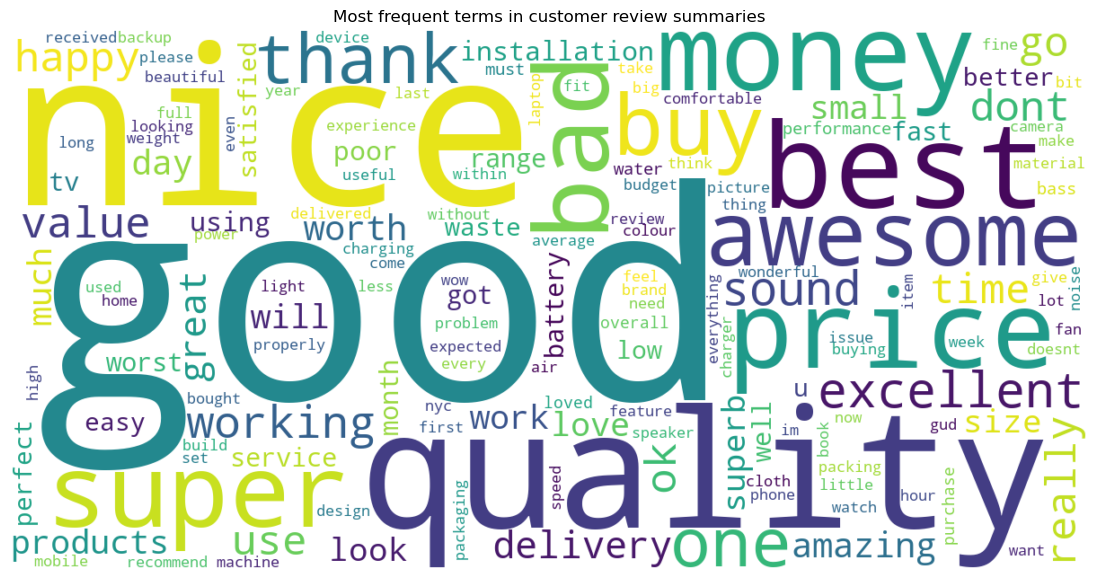

In [18]:
# Word cloud from the Summary column
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

text = ' '.join(df['Summary'].dropna().astype(str).str.lower())
stop = set(STOPWORDS) | {'product', 'flipkart', 'read', 'more'}
wc = WordCloud(width=1200, height=600, background_color='white',
               stopwords=stop, max_words=150, collocations=False).generate(text)

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation='bilinear'); plt.axis('off')
plt.title('Most frequent terms in customer review summaries')
plt.savefig('Exercise4_wordcloud.png', dpi=150, bbox_inches='tight')
plt.show()